In [14]:
from dotenv import load_dotenv
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.prompts import ChatPromptTemplate

load_dotenv()

llm = ChatGoogleGenerativeAI(model="gemini-3-flash-preview")

## Generator-Evaluator

> **Note:** This graph uses an iterative generator-evaluator workflow. The generator creates a joke about the requested topic, while the evaluator checks whether it is funny and provides feedback. If the joke is not funny, the feedback is sent back to the generator so it can improve the joke. The conditional function repeats this process until the joke is accepted or the maximum number of iterations is reached.

In [15]:
from pydantic import BaseModel, Field
from typing import TypedDict, Literal

class llm_schema(BaseModel):
    funny_flag: Literal['funny', 'not funny'] = Field(description="Whether the joke is funny or not")
    feedback: str = Field(description="Feedback on the joke")

llm_with_schema = llm.with_structured_output(llm_schema)

In [16]:
class graph_schema(TypedDict):
    topic: str
    joke: str
    funny_flag: str
    feedback: str
    max_iterations: int

#### Generator Node

In [17]:
def generator_node(state: graph_schema) -> graph_schema:

    topic = state['topic']

    if state['feedback']:
        response = llm.invoke(f"Please modify the following joke {state['joke']} based on the following feedback: {state['feedback']}") 
    else:
        response = llm.invoke(f"Create only one joke about the following topic: {topic}")
    
    state['joke'] = response.content 
    return state

#### Evaluator Node

In [18]:
def evaluator_node(state: graph_schema) -> graph_schema:

    joke = state['joke']
    iteration = state['max_iterations']

    prompt = ChatPromptTemplate.from_messages([
        ("system", "You are a comedy critic. Your job is to evaluate the following joke and provide feedback on how to make it funnier."),
        ("user", "Evaluate the following joke: {joke}\nRespond with 'funny' or 'not funny' and provide feedback if it's not funny.")
    ])

    chain = prompt | llm_with_schema
    response = chain.invoke({"joke": joke})

    state['funny_flag'] = response.funny_flag
    state['feedback'] = response.feedback
    state['max_iterations'] = iteration + 1

    return state

#### Conditional function

In [19]:
def conditional_func(state: graph_schema) -> str:

    iterations = state['max_iterations']

    if iterations <= 2 and state['funny_flag'] != 'funny':
        return "generator_node"
    else:
        return "end"

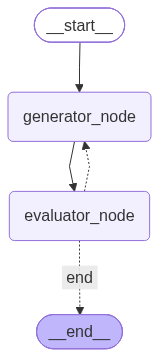

In [20]:
from langgraph.graph import StateGraph, START, END

graph = StateGraph(graph_schema)

graph.add_node("generator_node", generator_node)
graph.add_node("evaluator_node", evaluator_node)

graph.add_edge(START, "generator_node")
graph.add_edge("generator_node", "evaluator_node")
graph.add_conditional_edges("evaluator_node", conditional_func, {"generator_node":"generator_node", "end":END})

evaluator_graph = graph.compile()

from IPython.display import Image, display

# You could see the errors with the below command
Image(evaluator_graph.get_graph().draw_mermaid_png())

In [22]:
for chunk in evaluator_graph.stream(
    {
        "topic": "Cricket",
        "joke": "",
        "funny_flag": "",
        "feedback": "",
        "max_iterations": 0
    },
    stream_mode="updates"
):
    print(chunk)

{'generator_node': {'topic': 'Cricket', 'joke': [{'type': 'text', 'text': 'Why did the cricket player bring a rope to the match?\n\nBecause he wanted to tie the score!', 'extras': {'signature': 'Er0zCrozAWkUfRMJuBBMqAYgNEKvc+ZpYwzK27CCRS/SRgEQ9l7Ys7NZsol456mLrJ4eShmbTHWNjlaOPerOcgLCffzE8U1KBKZoO8nBaLPKUXlL0iVXikqn51Nsue6r4QPd1y6Advwg8npw//1lSotjIJmY93Qdolzj30tHXz7aZghYXaeTACubHvprdtqb8vugpObhjFp1O+Lym1wHaYa5cgQo3OnMxg/hylHBPM3zXiJ3gmBYxUB6mlLjJkrteLxlHLSVUbVDp+o6h6sl+ruE5AIxgMhTtiOQ5BBu9Ju9+DMwq2oTQ+vuRYakFLaSupTyAFtxx9GVrnYFQzUyBdb0spAziwMKgYjGWAZZRFuF650tKh6yGTvTi5xW5ibFrPxyOuxv6YoWOb+CrtydbiYOk/qzUXdHGt08t55HSk4A8426r8PNNJysVH5PD6OVxiHr/PcR5LBL7jdfBlTc/sONMseUwZQdk+FvX97gTPvmGhHZghSbAiuFhL18L0Mv7LyStH90E3dIYvtYa5XH/G4p1ix3xxaUsxtwM+65cey1coVPYmyjUlG3nL81YR9hC2QGAvDDBmmgoG5bvLEGBgUJ77OHCPpUuKHXzw4/bM2pQMFhnC87J+f4OqfEebrRlQKRh9MEvu0j0qqmPqOjJ/6JfXRjyzARoQyf7TKibAXZjm6bJlbE4G4H2d5tEhcIoBhocW48GDihU78cECrhHN0SlCaoM+8COxCoxJo3XKcjg4nllVYBKp6fe1iaGmtDuRWVul5TLFeIMASq2/Kw1HjC+hvvc8pQWDILD